In [ ]:
import os, sys
os.environ['R_HOME'] = '/home/caleb/miniconda3/envs/scFates/lib/R'
import re
import numpy as np
import pandas as pd
import scanpy as sc
import scanpy.external as sce
import scFates as scf
import matplotlib.pyplot as plt
from scipy.sparse.csgraph import connected_components
from sklearn.neighbors import NearestNeighbors
sc.settings.verbosity = 1
np.random.seed(0)

In [ ]:
name = os.path.basename(os.getcwd())
pth_ccca = os.path.abspath(os.path.join('..', '..', '..'))   # .../CCCA
sys.path.append(pth_ccca)
from scripts.load import load_CCCA_adata

In [ ]:
pth = os.path.join('..', '..', '..', '..')       # repo root (EMToolbox)
pth_data = os.path.join(pth, 'data')
base = re.sub(r'-\d+$', '', name)          # Chen2020_Head-and-Neck-4 -> Chen2020_Head-and-Neck
pth_in  = os.path.join(pth_data, 'unzip', 'CCCA', f'Data_{base}')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', 'Head-and-Neck', name)
pth_fig = os.path.join(pth, 'figures', 'mesencontext', 'claude', 'Head-and-Neck', name)
os.makedirs(pth_out, exist_ok=True); os.makedirs(os.path.join(pth_fig,'colorbars'), exist_ok=True)
print('dataset :', name); print('input   :', pth_in); print('root ok :', os.path.isdir(pth_data))

dataset : Chen2020_Head-and-Neck-4
input   : ../../../../../../data/unzip/CCCA/Data_Chen2020_Head-and-Neck
root ok : True


In [ ]:
# load dataset -> select malignant cells
adata = load_CCCA_adata(pth_in)
adata = adata[adata.obs.celltype == 'Malignant'].copy()
adata

Loading ../../../../../../data/unzip/CCCA/Data_Chen2020_Head-and-Neck
Done.


In [ ]:
# inspect per-sample malignant counts
n = adata.obs['sample'].value_counts().sort_values()
print(n.to_string())

sample
P09       4
P15       5
P10       6
P07      13
P08      25
P02      36
P03     107
P04     112
P05     136
P14     197
P06     234
P12     236
P01     838
P11    1814


In [ ]:
# Data-driven sample threshold: largest multiplicative gap in sorted counts,
# subject to retaining >=3 samples and >=80% of malignant cells (excludes the
# under-populated tail without collapsing to the 1-2 dominant patients).
vals = n.values; tot = vals.sum(); best = None
for i in range(len(vals) - 1):
    kept_s = len(vals) - (i + 1); kept_c = vals[i + 1:].sum()
    if kept_s >= 3 and kept_c >= 0.8 * tot:
        ratio = vals[i + 1] / max(vals[i], 1)
        if best is None or ratio > best[0]:
            best = (ratio, vals[i + 1], kept_s, kept_c)
ratio, thr, ks, kc = best
print(f'threshold: keep samples with >= {thr} cells  (gap ratio {ratio:.2f})')
print(f'retains {ks} samples / {kc} cells ({100*kc/tot:.1f}% of malignant)')
keep = n.index[n >= thr]
adata = adata[adata.obs['sample'].isin(keep)].copy()
adata

threshold: keep samples with >= 107 cells  (gap ratio 2.97)
retains 8 samples / 3674 cells (97.6% of malignant)


Finding overdispersed features
    computing mean and variances
    gam fitting
    found 1290 over-dispersed features (0:00:01) --> added 
    .var['res'], residuals of GAM fit.
    .var['lp'], p-value.
    .var['lpa'], BH adjusted p-value.
    .var['qv'], percentile of qui-squared distribution.
    .var['highly_variable'], feature is over-dispersed.

over-dispersed features: 1290


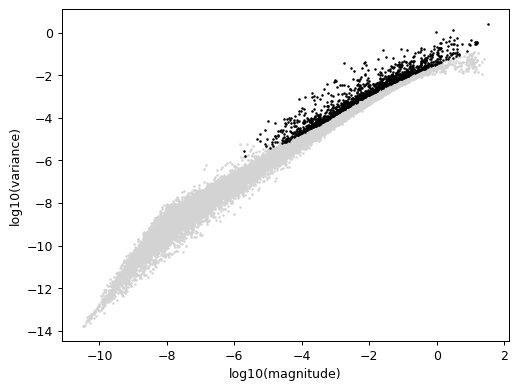

In [ ]:
# filter genes + select over-dispersed features (NO sc.pp.scale before PCA)
sc.pp.filter_genes(adata, min_cells = 3)
scf.pp.find_overdispersed(adata, plot = True)
print('over-dispersed features:', int(adata.var.highly_variable.sum()))

In [ ]:
# PCA (on log-normalized counts, no scaling) -> Harmony integrate on 'sample'.
# GATE 1 (mixing): sweep integration strength theta; quantify per-neighborhood
# batch mixing with iLISI (inverse-Simpson on sample labels within k-NN).
sc.pp.pca(adata, n_comps = 50)
# n_pcs DERIVED from this dataset's variance spectrum (spec C1: not inherited; C2: shown).
# The spectrum is a long gentle tail with no sharp elbow, so a chord/Kneedle elbow
# over-cuts (here to ~8) and under-powers the manifold -> a patient-segregated read
# (an explicitly-flagged failure mode). Instead retain every PC that individually
# explains > 0.5% of total variance -- a fixed variance floor, not an inherited count.
# Sanity-checked against the platform precedent: this lands at the 10x scale
# (Kürten 20), distinct from SmartSeq2 (Puram 40); Chen is 10x like Kürten.
vr = adata.uns['pca']['variance_ratio']
n_pcs = int((vr > 0.005).sum())
print(f'n_pcs = {n_pcs}  (PCs with >0.5% variance; PC{n_pcs}={vr[n_pcs-1]*100:.2f}%, '
      f'PC{n_pcs+1}={vr[n_pcs]*100:.2f}%). 10x scale; cf. Kürten 20, Puram 40=SmartSeq2. '
      f'Chord elbow would give {int(np.argmax(np.abs((vr[-1]-vr[0])*np.arange(len(vr))-(len(vr)-1)*vr+(len(vr)-1)*vr[0])/np.hypot(vr[-1]-vr[0],len(vr)-1)))+1} (over-cuts).')

def ilisi(rep, labels, k = 90):
    nn = NearestNeighbors(n_neighbors = k).fit(rep)
    _, idx = nn.kneighbors(rep)
    lab = pd.Categorical(labels).codes; B = lab.max() + 1
    out = np.empty(len(rep))
    for i in range(len(rep)):
        c = np.bincount(lab[idx[i]], minlength = B) / k
        out[i] = 1.0 / np.sum(c ** 2)
    return out

samples = adata.obs['sample'].values
p = adata.obs['sample'].value_counts(normalize = True).values
ceiling = 1.0 / np.sum(p ** 2)
il_pre = ilisi(adata.obsm['X_pca'][:, :n_pcs], samples)
print(f'iLISI ceiling (perfect mixing, {adata.obs["sample"].nunique()} samples) = {ceiling:.2f}')
print(f'iLISI pre-integration: mean {il_pre.mean():.2f}')
reps = {}
for th in [0.5, 1, 2, 4, 8]:
    sce.pp.harmony_integrate(adata, 'sample', theta = th, max_iter_harmony = 20,
                             random_state = 0, verbose = False)
    reps[th] = adata.obsm['X_pca_harmony'].copy()
    il = ilisi(reps[th][:, :n_pcs], samples)
    print(f'theta={th}: iLISI mean {il.mean():.2f}  ({100*il.mean()/ceiling:.0f}% of ceiling)')

n_pcs = 19  (PCs with >0.5% variance; PC19=0.54%, PC20=0.49%). 10x scale; cf. Kürten 20, Puram 40=SmartSeq2. Chord elbow would give 8 (over-cuts).
iLISI ceiling (perfect mixing, 8 samples) = 3.23
iLISI pre-integration: mean 1.08
theta=0.5: iLISI mean 1.21  (38% of ceiling)
theta=1: iLISI mean 1.36  (42% of ceiling)
theta=2: iLISI mean 2.28  (71% of ceiling)
theta=4: iLISI mean 2.33  (72% of ceiling)
theta=8: iLISI mean 2.35  (73% of ceiling)


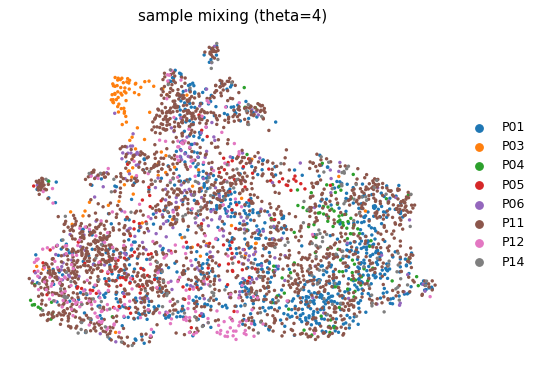

In [ ]:
# theta=4 gives near-plateau mixing and a single connected graph (checked below)
# without the over-smoothing of theta=8 -> minimal-sufficient integration.
theta = 4
adata.obsm['X_pca_harmony'] = reps[theta]
adata.uns.pop('harmony', None)
sc.pp.neighbors(adata, use_rep = 'X_pca_harmony', n_pcs = n_pcs, random_state = 0)
sc.tl.umap(adata, random_state = 0)
sc.pl.umap(adata, color = ['sample'], size = 30, frameon = False,
           title = f'sample mixing (theta={theta})')

In [ ]:
# GATE 1 (continuity): the integrated k-NN graph must be a single connected
# component (no detached islands / archipelago).
ncomp, lab = connected_components(adata.obsp['connectivities'], directed = False)
sizes = np.bincount(lab)
print(f'connected components: {ncomp}   component sizes: {sorted(sizes, reverse=True)[:6]}')
il4 = ilisi(reps[theta][:, :n_pcs], samples)
print(f'GATE 1: iLISI {il_pre.mean():.2f} -> {il4.mean():.2f} of {ceiling:.2f} ceiling; '
      f'{ncomp} component(s) -> {"PASS" if ncomp==1 else "REVIEW"}')

connected components: 1   component sizes: [np.int64(3674)]
GATE 1: iLISI 1.08 -> 2.33 of 3.23 ceiling; 1 component(s) -> PASS


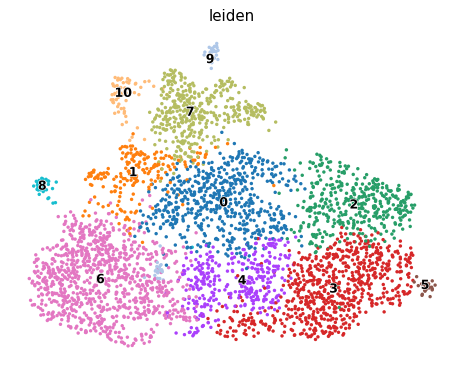

In [ ]:
# cluster -> inspect for any detached / doublet clusters
sc.tl.leiden(adata, resolution = 0.6, flavor = 'igraph', n_iterations = 2,
             directed = False, random_state = 0)
sc.pl.umap(adata, color = 'leiden', size = 30, legend_loc = 'on data',
           legend_fontoutline = True, frameon = False)

In [ ]:
# top markers per cluster (Wilcoxon) to assign malignant programs
sc.tl.rank_genes_groups(adata, 'leiden', method = 'wilcoxon')
for cl in adata.obs.leiden.cat.categories:
    print(cl, [adata.uns['rank_genes_groups']['names'][cl][i] for i in range(10)])

0 ['S100A11', 'KRT5', 'S100A2', 'HSPB1', 'FXYD3', 'TXNDC17', 'SFN', 'KRT19', 'ANXA2', 'S100A6']
1 ['S100A6', 'SAT1', 'TACSTD2', 'ANXA2', 'NEAT1', 'S100A11', 'CSTB', 'KRT6A', 'SLPI', 'TMSB10']
2 ['RPL35A', 'RPL17', 'RPS27A', 'RPL18A', 'RPL31', 'RPS17', 'RPS10', 'RPS18', 'RPL32', 'RPL15']
3 ['H2AFZ', 'TUBA1B', 'YBX1', 'CHCHD2', 'RAN', 'HMGN2', 'HMGB2', 'NME2', 'PCLAF', 'SNRPF']
4 ['HMGB2', 'TOP2A', 'TUBA1B', 'UBE2C', 'CENPF', 'MKI67', 'NUSAP1', 'CKS1B', 'NUCKS1', 'BIRC5']
5 ['CLDN4', 'HLA-DRA', 'EEF2', 'SLC25A3', 'HLA-DPB1', 'ATP5F1A', 'HLA-DRB1', 'PNRC1', 'HLA-DQA1', 'CD24']
6 ['MT-ND4', 'MT-CO2', 'MT-CO3', 'MT-ND3', 'MT-ND2', 'MT-CYB', 'MT-ATP6', 'MT-CO1', 'MT-ND1', 'MT-ND5']
7 ['RPL10', 'RPL10A', 'RPL13A', 'RPS27', 'RPL28', 'RPS12', 'RPS4X', 'RPL31', 'RPS9', 'RPL39']
8 ['TMSB4X', 'MALAT1', 'PTPRC', 'ACTB', 'CRIP1', 'EIF5A', 'B2M', 'SAT1', 'CD2', 'WTAP']
9 ['RPS4X', 'PNRC1', 'ANKRD29', 'HLA-DRA', 'NOP53', 'HLA-DPB1', 'EEF1A1', 'RPL10A', 'EEF2', 'RPS27']
10 ['PRSS27', 'H2AFJ', 'NDRG2', 

subtype
MT-high                    919
Ribosomal-high             831
Cycling-S                  694
Basal                      571
Cycling-G2M                336
Differentiated             200
Differentiated-squamous     57
Immune-doublet              39
Epithelial-APM              27


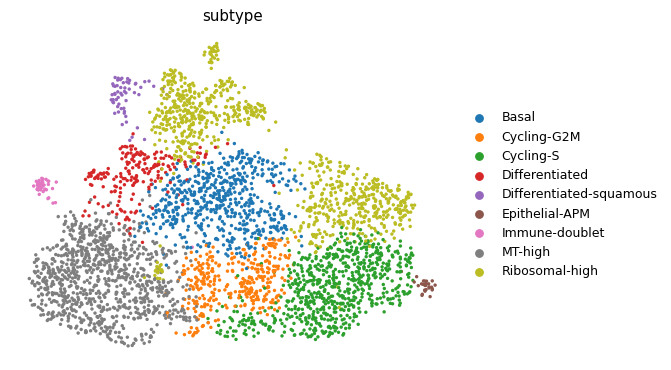

In [ ]:
# annotate malignant programs from markers.  Chen et al. 2020 (NPC) describe
# malignant epithelial programs spanning basal/differentiated squamous states,
# a cycling compartment, and stress/metabolic states -- recapitulated here.
celltype_dict = {
    '0':'Basal', '1':'Differentiated', '2':'Ribosomal-high', '3':'Cycling-S',
    '4':'Cycling-G2M', '5':'Epithelial-APM', '6':'MT-high', '7':'Ribosomal-high',
    '8':'Immune-doublet', '9':'Ribosomal-high', '10':'Differentiated-squamous'}
adata.obs['subtype'] = adata.obs.leiden.map(celltype_dict).astype('category')
adata.obs['celltype'] = adata.obs['subtype']
sc.pl.umap(adata, color = 'subtype', size = 30, frameon = False)
print(adata.obs['subtype'].value_counts().to_string())

In [ ]:
adata.uns['integration'] = {'method':'harmony', 'batch':'sample',
    'theta':float(theta), 'n_pcs':int(n_pcs),
    'ilisi_pre':float(il_pre.mean()), 'ilisi_post':float(il4.mean()),
    'ilisi_ceiling':float(ceiling), 'n_components':int(ncomp)}
adata.write(os.path.join(pth_out, 'processed.h5ad'))
print('saved processed.h5ad', adata.shape)

saved processed.h5ad (3674, 22080)


saved samples.pdf -> ../../../../../../figures/cancer/vertebrate/CCCA/Claude/Head-and-Neck/Chen2020_Head-and-Neck-4


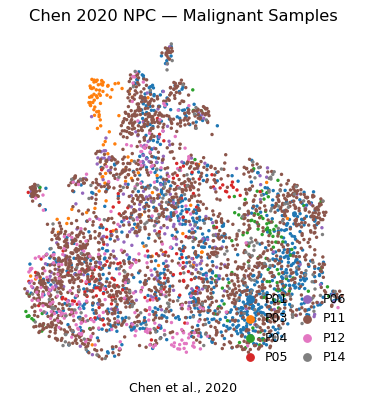

In [ ]:
# GATE 1 deliverable: single sample-colored manifold UMAP (reference layout)
fig, ax = plt.subplots(1, 1, figsize = (5, 5))
sc.pl.umap(adata, color = 'sample', size = 30, frameon = False, show = False, ax = ax)
handles, labels = ax.get_legend_handles_labels()
ax.legend(handles, labels, ncol = 2, frameon = False, loc = 'lower right',
          columnspacing = .5, handletextpad = .25)
ax.set_title('Chen 2020 NPC — Malignant Samples', size = 13)
ax.text(.5, -.05, 'Chen et al., 2020', ha = 'center', transform = ax.transAxes)
fig.savefig(os.path.join(pth_fig, 'samples.pdf'), bbox_inches = 'tight')
print('saved samples.pdf ->', pth_fig)